# Phase 2 – Part A: Unsupervised Learning
**SWE485 – Group 4 – University Student Retention & Advisory Dashboard**

| Section | Owner |
|---|---|
| K-Means: rationale, data preparation, choosing *k*, implementation, cluster profiles, saved model, Random Forest + cluster-feature test | Najd Al Ghanim |
| Agglomerative clustering: rationale, choosing *k*, algorithm comparison (Silhouette, Davies-Bouldin, WCSS, BCubed), all cluster visualizations, Integration Strategy, Challenges & Limitations | Yusra Al Helal |

**Agreed setting:** `K = 3` clusters for both algorithms (justified in Sections 3.1 and 3.2).


## 0. Setup (shared)
Imports, paths and data loading used by all sections.

In [13]:
# ============================================================
# Setup: imports, paths, data
# ============================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
K = 3   # must match the K chosen in the K-Means section

# Works whether the notebook is run from the repo root or from Unsupervised_Learning/
ROOT = Path(".") if Path("Dataset").exists() else Path("..")
PLOTS = ROOT / "Unsupervised_Learning" / "plots"
OUTPUTS = ROOT / "Unsupervised_Learning" / "outputs"
PLOTS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(ROOT / "Dataset" / "preprocessed_data.csv")
raw = pd.read_csv(ROOT / "Dataset" / "data.csv", sep=None, engine="python")
raw.columns = [c.strip() for c in raw.columns]

# Clustering input: remove the class label (and the split marker). Features are already
# encoded and scaled in Phase 1, so no extra scaling is applied here.
X = df.drop(columns=["Target", "split"]).values
feature_names = df.drop(columns=["Target", "split"]).columns

# Ground truth is kept ONLY for external validation (BCubed) and for profiling.
TARGET_NAMES = {0: "Dropout", 1: "Enrolled", 2: "Graduate"}
y_true = df["Target"].map(TARGET_NAMES).values

# Rows of preprocessed_data.csv are in the same order as data.csv
assert (raw["Target"].values == y_true).all()
print("Clustering matrix:", X.shape)

Clustering matrix: (4424, 102)


## 1. Clustering Rationale & Algorithm Selection

### 1.1 Algorithm 1 – K-Means

K-Means is our first algorithm. It starts from K initial centers, assigns every student to the nearest center, moves each center to the average of its students, and repeats until the groups stop changing. Each cluster is described by its center, the "average student" of that group.

**Dataset size and feature types.** After preprocessing, the data has 4,424 students and 102 features: 14 numeric features (13 standardized features and the `academic_progress` ratio) and 88 binary (0/1) features. The course slides note that K-Means needs numeric input and is not designed for categorical attributes (K-Modes is the alternative for those). Our categorical features were one-hot encoded, so every column is numeric, and the "average" of a 0/1 column is simply the share of students in the group. This makes K-Means usable here, although less natural than for purely numeric data (see the limitations below). With only 4,424 students, one K-Means fit takes well under a second, so we can try many values of *k* and use several random starts (`n_init = 10`).

**Expected cluster shape.** K-Means builds compact, roughly spherical clusters. This matches what we expect from our students: groups of similar profiles (for example, students who passed most of their units versus students who passed almost none), not long or irregular shapes.

**Scalability and interpretability.** K-Means is a linear algorithm (time O(tkn) for t iterations, k clusters and n students), so it would still work for a much larger cohort. Its clusters are easy to explain to advisors, because each one is summarized by the average values of its students. It also has a `predict()` method, so a new student can be assigned to a cluster in the dashboard without refitting the model. This is the main reason K-Means is the clustering model we plan to deploy.

**Limitations we accept.** K-Means depends on its starting centers, which we reduce with `n_init = 10` and a fixed `random_state`. It uses Euclidean distance, which is less informative when most features are 0/1, so we expect modest separation scores. It also needs *k* to be chosen in advance (Section 3.1), and it is sensitive to outliers such as very high ages.

### 1.2 Algorithm 2 – Agglomerative Clustering (Ward linkage)

For the second algorithm we considered three options:

| Option | Fit for our data | Decision |
|---|---|---|
| **Agglomerative (Ward)** | 4,424 rows is small enough for hierarchical clustering (O(n²) memory ≈ 150 MB). Deterministic (no random initialization). The dendrogram shows the cluster hierarchy and helps choose *k*. Ward minimizes within-cluster variance, so its WCSS is directly comparable with K-Means. | **Selected** |
| Gaussian Mixture (GMM) | Assumes each cluster is a Gaussian. Most of our 102 features are 0/1 one-hot columns, which breaks this assumption, and full covariance in 102 dimensions is unstable. | Rejected (checked below) |
| DBSCAN | Needs a meaningful density/distance. In 102 mostly-binary dimensions distances become similar, so choosing `eps` is unreliable and most points end up as noise or one cluster. | Rejected |

**Expected cluster shape:** Ward builds compact, roughly spherical groups (like K-Means), but it builds them bottom-up, so it can follow
the hierarchy of the data instead of depending on random centroids. **Interpretability:** high – each merge can be read from the dendrogram.
**Scalability:** limited (O(n²)), acceptable for our dataset but a known limitation for larger cohorts.

The quick check below supports rejecting GMM: its silhouette is lower than Agglomerative's for every *k* from 2 to 6, and much lower at k = 2 and k = 3 (0.07 and 0.10, versus 0.28 and 0.20).

In [14]:
# Quick evidence for the algorithm choice (GMM uses diagonal covariance to stay numerically stable)
rows = []
for k in range(2, 7):
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    gm = GaussianMixture(n_components=k, covariance_type="diag", random_state=RANDOM_STATE, n_init=3).fit(X).predict(X)
    rows.append({"k": k,
                 "Agglomerative silhouette": silhouette_score(X, ag),
                 "GMM silhouette": silhouette_score(X, gm)})
display(pd.DataFrame(rows).round(3).set_index("k"))

,Agglomerative silhouette,GMM silhouette
k,,
2,0.276,0.072
3,0.195,0.103
4,0.095,0.074
5,0.103,0.041
6,0.078,0.053


## 2. Data Preparation (target removal, feature scaling)

### 2.1 Removing the class label

Clustering is unsupervised, so the algorithm must not see the outcome. The `Target` column (Dropout, Enrolled, Graduate) is therefore removed from the clustering input, together with the `split` column, which only marks the Phase 1 train/test rows. The remaining 102 columns form the matrix `X` (4,424 students × 102 features).

The true outcomes are kept in a separate variable (`y_true`). They are **not** used to build the clusters. They are used only afterwards to describe each cluster (for example, its dropout rate) and for the external BCubed evaluation.

### 2.2 Feature scaling

No new scaling is needed. In Phase 1 the 13 numeric features were already standardized (average 0, standard deviation 1), the categorical features were one-hot encoded as 0/1 columns, and the engineered `academic_progress` ratio already lies between 0 and 1. Because K-Means is based on Euclidean distance, features on very different scales would dominate the result. Here the features are on comparable scales, so no feature dominates only because of its units.

The Setup cell also checks that the rows of `preprocessed_data.csv` and `data.csv` are in the same order. This allows us to show readable, original-unit values (such as age in years) when we describe the clusters.

## 3. Cluster Determination & Implementation

### 3.1 K-Means: choosing k

We try k = 2 to 8 and look at three things: the **elbow plot** (WCSS, where the improvement slows down), the **silhouette score** (how well separated the clusters are), and how useful the resulting groups are for advising. The table below also shows the dropout rate of the riskiest cluster for each k, because the purpose of the clusters is to point advisors to students who need support.

,WCSS,Silhouette,Davies-Bouldin,Smallest cluster,Dropout rate of the riskiest cluster
k,,,,,
2,78414.442,0.305,1.564,301,0.327
3,70788.632,0.192,2.009,291,0.796
4,67088.466,0.095,2.411,279,0.794
5,64157.661,0.077,2.520,273,0.786
6,61571.247,0.085,2.302,113,0.788
7,59028.556,0.087,2.230,104,0.786
8,56775.436,0.088,2.159,54,0.784


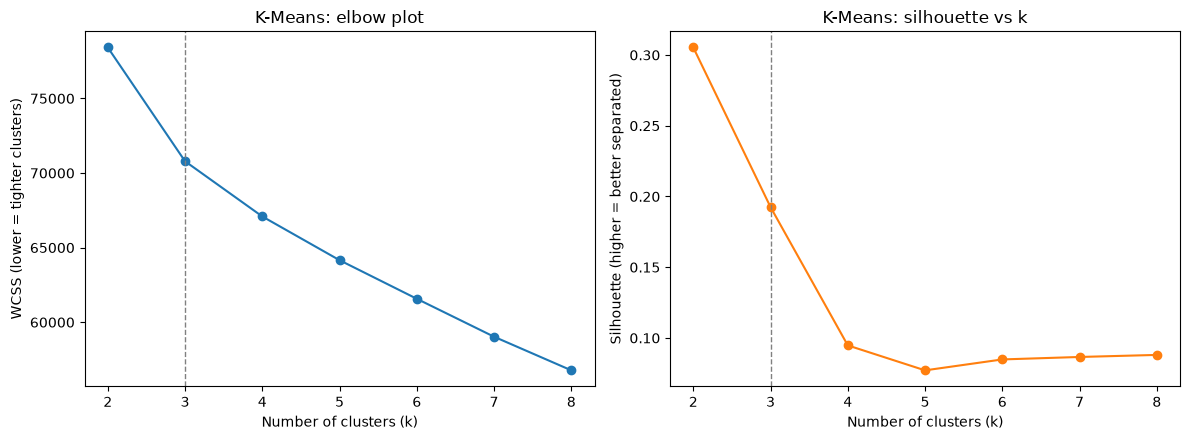

Final K-Means fitted with K = 3. Cluster sizes: [291, 3409, 724]


In [15]:
# ============================================================
# 3.1 K-Means: choosing k (elbow + silhouette)
# ============================================================
k_values = range(2, 9)
km_rows = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    km_rows.append({"k": k,
                    "WCSS": km.inertia_,
                    "Silhouette": silhouette_score(X, km.labels_),
                    "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
                    "Smallest cluster": np.bincount(km.labels_).min(),
                    "Dropout rate of the riskiest cluster": max(
                        (y_true[km.labels_ == c] == "Dropout").mean() for c in range(k))})
km_table = pd.DataFrame(km_rows).set_index("k")
display(km_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(km_table.index, km_table["WCSS"], marker="o")
axes[0].axvline(K, color="grey", ls="--", lw=1)
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("WCSS (lower = tighter clusters)")
axes[0].set_title("K-Means: elbow plot")

axes[1].plot(km_table.index, km_table["Silhouette"], marker="o", color="tab:orange")
axes[1].axvline(K, color="grey", ls="--", lw=1)
axes[1].set_xlabel("Number of clusters (k)"); axes[1].set_ylabel("Silhouette (higher = better separated)")
axes[1].set_title("K-Means: silhouette vs k")
plt.tight_layout(); plt.savefig(PLOTS / "kmeans_k_selection.png", dpi=150); plt.show()

# Final K-Means model with the agreed K
kmeans_final = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
print(f"Final K-Means fitted with K = {K}. Cluster sizes:", np.bincount(kmeans_final.labels_).tolist())

**Choice: k = 3.**
- **Elbow:** WCSS decreases smoothly, so there is no sharp elbow. The biggest improvement is from k = 2 to k = 3 (about 7,600), and the gains after that are smaller (about 3,700, then 2,900), so the curve bends around k = 3.
- **Silhouette:** the highest value is at k = 2 (0.31). The course rule is to choose the k with the highest silhouette, but here we deliberately choose a different value: with k = 2 the riskiest cluster has a dropout rate of only 33%, so it does not point advisors to a high-risk group. With k = 3 a distinct group appears whose dropout rate is about 80%.
- **From k = 4 onwards** the silhouette drops to about 0.1 or lower, and the riskiest cluster stays at about 79%, so extra clusters add complexity without new decision value.
- We therefore use **k = 3**, the same value as the Agglomerative model (Section 3.2). The final K-Means model is fitted with `n_init = 10` and `random_state = 42` and is stored as `kmeans_final` for the profiles and the saved model.

### 3.2 Agglomerative clustering: choosing k

We use two complementary methods:
1. **Silhouette and Davies-Bouldin for k = 2…8** (higher silhouette and lower DBI are better).
2. **Dendrogram (Ward)** – a large vertical jump before a merge means two distinct groups are being forced together.

,Silhouette,Davies-Bouldin,Smallest cluster
k,,,
2,0.276,1.636,320
3,0.195,2.084,320
4,0.095,2.292,320
5,0.103,2.035,40
6,0.078,2.473,40
7,0.078,2.426,40
8,0.060,2.430,40


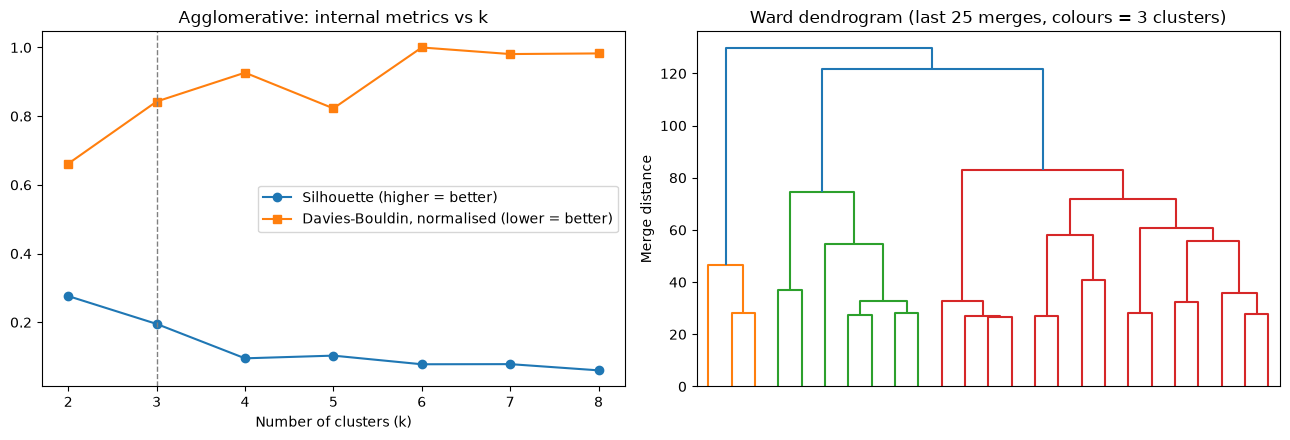

In [16]:
k_rows = []
for k in range(2, 9):
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    k_rows.append({"k": k,
                   "Silhouette": silhouette_score(X, labels),
                   "Davies-Bouldin": davies_bouldin_score(X, labels),
                   "Smallest cluster": np.bincount(labels).min()})
k_table = pd.DataFrame(k_rows).set_index("k")
display(k_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_table.index, k_table["Silhouette"], marker="o", label="Silhouette (higher = better)")
axes[0].plot(k_table.index, k_table["Davies-Bouldin"] / k_table["Davies-Bouldin"].max(), marker="s",
             label="Davies-Bouldin, normalised (lower = better)")
axes[0].axvline(K, color="grey", ls="--", lw=1)
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_title("Agglomerative: internal metrics vs k"); axes[0].legend()

Z = linkage(X, method="ward")
dendrogram(Z, truncate_mode="lastp", p=25, ax=axes[1], no_labels=True, color_threshold=Z[-K + 1, 2])
axes[1].set_title(f"Ward dendrogram (last 25 merges, colours = {K} clusters)")
axes[1].set_ylabel("Merge distance")
plt.tight_layout(); plt.savefig(PLOTS / "agglomerative_k_selection.png", dpi=150); plt.show()

**Choice: k = 3.**
- k = 2 has the highest silhouette (0.276, so the usual "highest silhouette" rule would choose it), but it only separates a small group of ~320 students from everyone else, which is not useful for advising.
- k = 3 has a lower silhouette than k = 2 (0.195 versus 0.276), but it adds a clearly meaningful group: students with almost no passed units in the 1st semester (≈80% dropout, see profiles below).
- From k = 4 the silhouette drops sharply (≈0.10) and the new splits do not change dropout rates, so they add complexity without decision value.
- In the dendrogram the last two merges are much taller than the rest, which also supports 2–3 clusters.

Both algorithms are therefore compared at the same `K = 3`.

## 4. Evaluation Metrics & Visualizations

### 4.1 Comparison of the two algorithms

Metrics:
- **Silhouette** (−1 to 1, higher = better separated)
- **Davies-Bouldin Index** (≥ 0, lower = better)
- **WCSS** – total within-cluster sum of squares (lower = more compact; computed the same way for both algorithms)
- **BCubed Precision / Recall / F1** against the true outcome (Dropout / Enrolled / Graduate). This is external validation only; the label was **not** used for clustering.

In [17]:
def wcss(X, labels):
    # Total within-cluster sum of squares, computed identically for any clustering
    return sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels))

def bcubed(labels, truth):
    # BCubed precision/recall/F1 using the cluster-by-class contingency table
    ct = pd.crosstab(labels, truth).values.astype(float)
    n = ct.sum()
    precision = (ct ** 2 / ct.sum(axis=1, keepdims=True)).sum() / n
    recall = (ct ** 2 / ct.sum(axis=0, keepdims=True)).sum() / n
    return precision, recall, 2 * precision * recall / (precision + recall)

kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
agglo = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)
labels = {"K-Means": kmeans.labels_, "Agglomerative (Ward)": agglo.labels_}

comparison = []
for name, lab in labels.items():
    p, r, f = bcubed(lab, y_true)
    comparison.append({"Algorithm": name,
                       "Silhouette ↑": silhouette_score(X, lab),
                       "Davies-Bouldin ↓": davies_bouldin_score(X, lab),
                       "WCSS ↓": wcss(X, lab),
                       "BCubed Precision ↑": p, "BCubed Recall ↑": r, "BCubed F1 ↑": f,
                       "Cluster sizes": sorted(np.bincount(lab).tolist(), reverse=True)})
comparison = pd.DataFrame(comparison).set_index("Algorithm")
comparison.round(3).to_csv(OUTPUTS / "clustering_comparison.csv")
display(comparison.round(3))

print("Adjusted Rand Index between the two algorithms:",
      round(adjusted_rand_score(labels["K-Means"], labels["Agglomerative (Ward)"]), 3))

,Silhouette ↑,Davies-Bouldin ↓,WCSS ↓,BCubed Precision ↑,BCubed Recall ↑,BCubed F1 ↑,Cluster sizes
Algorithm,,,,,,,
K-Means,0.192,2.009,70788.632,0.461,0.678,0.548,"[3409, 724, 291]"
Agglomerative (Ward),0.195,2.084,71568.212,0.459,0.666,0.543,"[3374, 730, 320]"


Adjusted Rand Index between the two algorithms: 0.946


**Interpretation of the comparison**
- **Internal metrics are almost tied.** Silhouette, Davies-Bouldin and WCSS differ only slightly. K-Means has a marginally lower WCSS,
  which is expected because WCSS is exactly what K-Means optimizes.
- **The two algorithms find essentially the same structure** – the Adjusted Rand Index is very high, so the clusters are not an artifact of one method.
- **The absolute silhouette is modest (≈0.2).** This is typical for 102 dimensions where most columns are one-hot: distances become similar,
  so clusters overlap even when they are meaningful.
- **BCubed:** precision is moderate (about 0.46) and recall is higher (about 0.68) because one large cluster contains most Graduates *and* most Enrolled students.
  Clusters do not reproduce the three outcomes – which is expected: they group students by *profile*, not by outcome.
  The one cluster that does align with an outcome is the "no academic progress" group, which is mostly Dropout.

**Practical winner: K-Means.** With almost equal quality, K-Means is preferred for the system because it has a `predict()` method
and can assign a *new* student to a cluster in the dashboard. Agglomerative clustering cannot label new points without refitting.
Agglomerative is kept as a validation method that confirms the K-Means structure.

### 4.2 2D projections (PCA and t-SNE)
PCA is linear and shows global structure; t-SNE preserves local neighborhoods and usually separates groups more visibly.

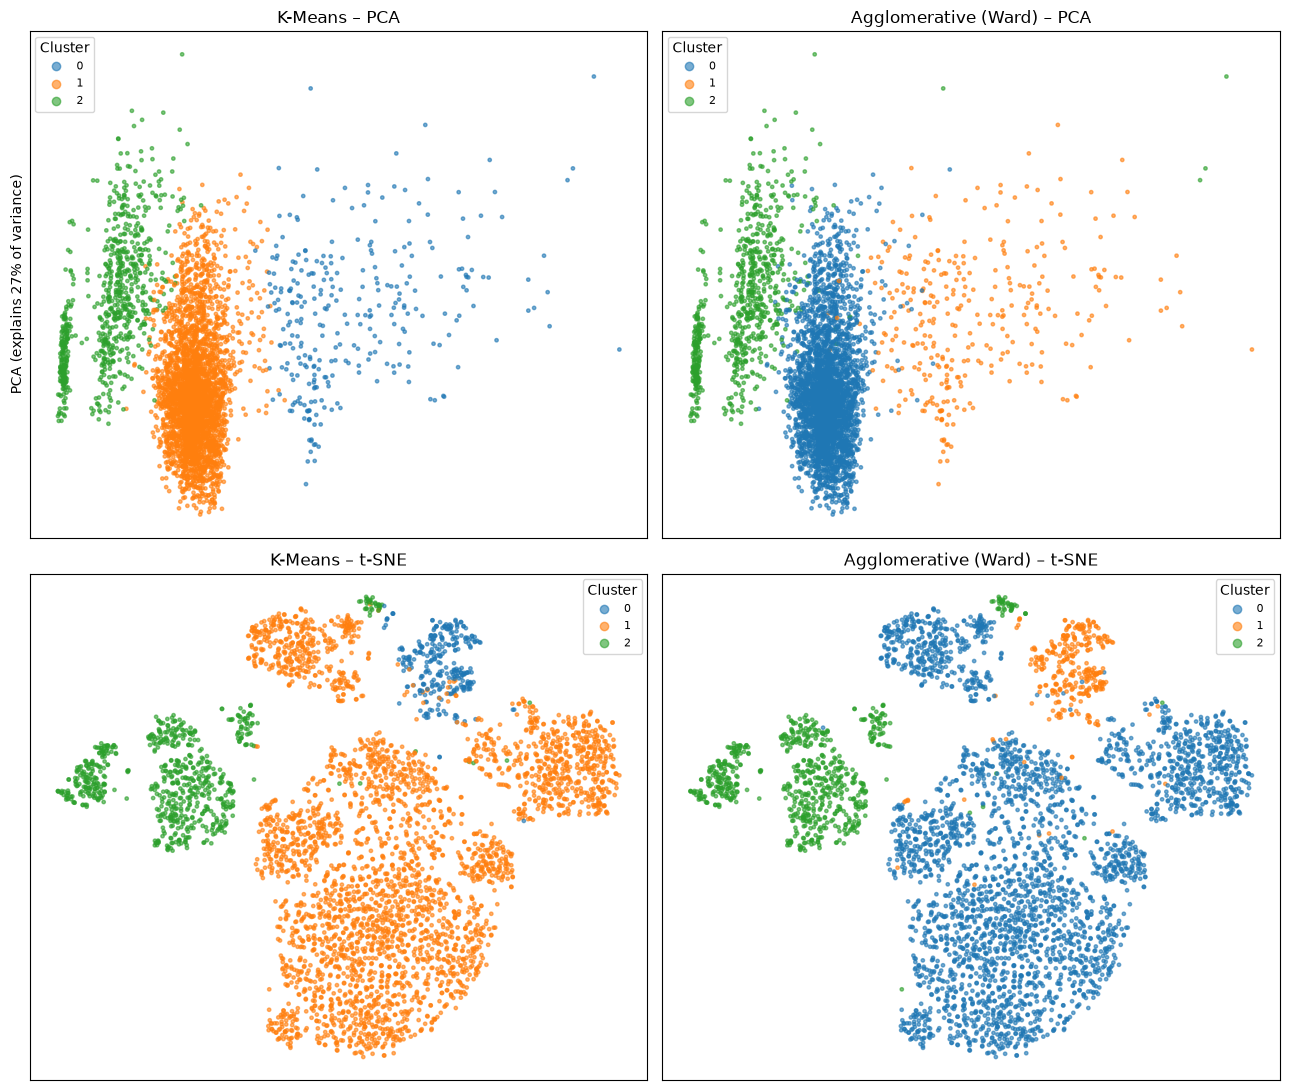

In [18]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
X_tsne = TSNE(n_components=2, perplexity=40, init="pca", random_state=RANDOM_STATE).fit_transform(X)

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
for col, (name, lab) in enumerate(labels.items()):
    for row, (proj, title) in enumerate([(X_pca, "PCA"), (X_tsne, "t-SNE")]):
        ax = axes[row, col]
        sc = ax.scatter(proj[:, 0], proj[:, 1], c=lab, cmap="tab10", s=6, alpha=0.6, vmin=0, vmax=9)
        ax.set_title(f"{name} – {title}")
        ax.set_xticks([]); ax.set_yticks([])
        ax.legend(*sc.legend_elements(), title="Cluster", loc="best", fontsize=8)
axes[0, 0].set_ylabel(f"PCA (explains {pca.explained_variance_ratio_.sum():.0%} of variance)")
plt.tight_layout(); plt.savefig(PLOTS / "clusters_pca_tsne.png", dpi=150); plt.show()

### 4.3 Cluster size distribution, and outcome mix inside each cluster

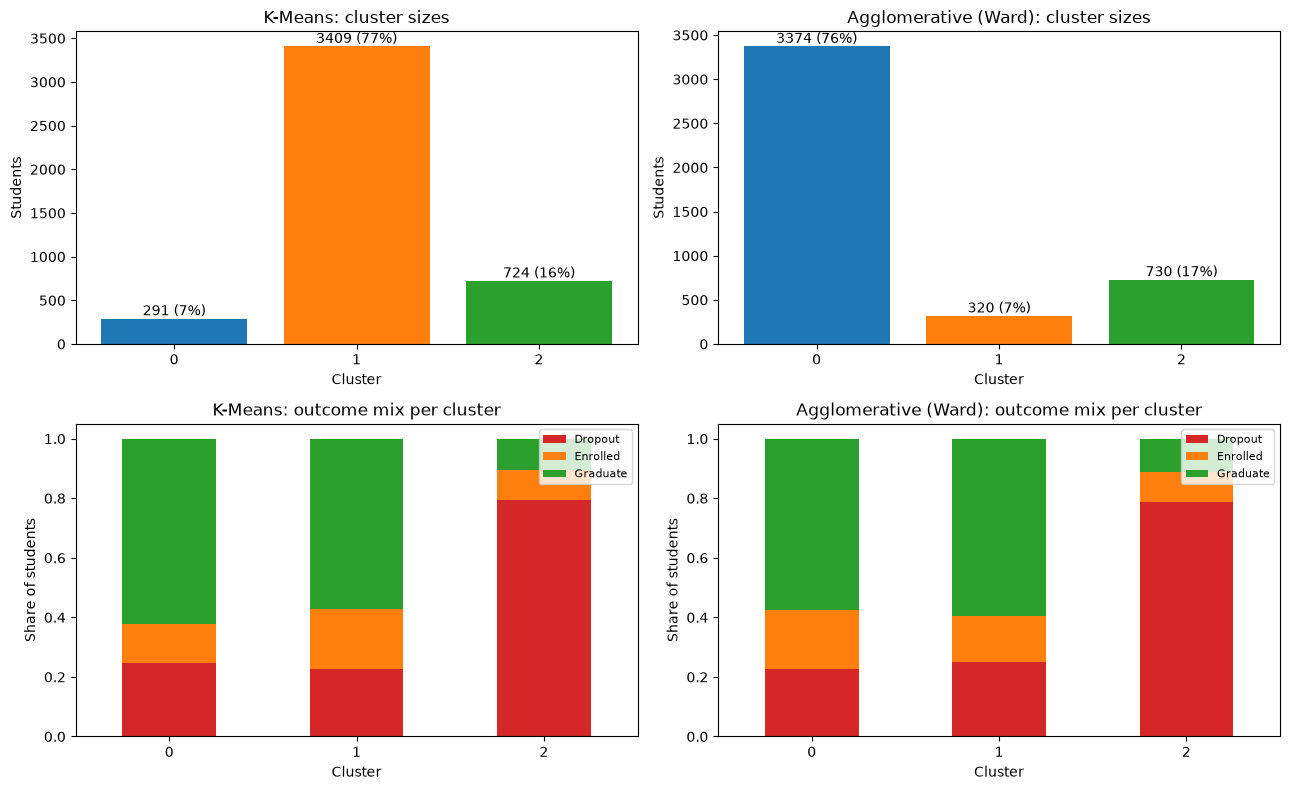

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for col, (name, lab) in enumerate(labels.items()):
    sizes = pd.Series(lab).value_counts().sort_index()
    axes[0, col].bar(sizes.index.astype(str), sizes.values, color=sns.color_palette("tab10", K))
    for i, v in enumerate(sizes.values):
        axes[0, col].text(i, v, f"{v} ({v / len(lab):.0%})", ha="center", va="bottom")
    axes[0, col].set_title(f"{name}: cluster sizes"); axes[0, col].set_xlabel("Cluster"); axes[0, col].set_ylabel("Students")

    mix = pd.crosstab(lab, y_true, normalize="index")[["Dropout", "Enrolled", "Graduate"]]
    mix.plot(kind="bar", stacked=True, ax=axes[1, col], color=["#d62728", "#ff7f0e", "#2ca02c"], rot=0)
    axes[1, col].set_title(f"{name}: outcome mix per cluster"); axes[1, col].set_xlabel("Cluster")
    axes[1, col].set_ylabel("Share of students"); axes[1, col].legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(PLOTS / "cluster_sizes_and_outcomes.png", dpi=150); plt.show()

### 4.4 Feature means per cluster and feature importance per cluster
Means are shown in **original units** (from `data.csv`) so they are readable. "Importance" for a cluster is how far the cluster's mean is from the
overall mean, measured in standard deviations: large positive/negative values are the features that define that cluster.

,0,1,2
Age at enrollment,22.16,29.09,25.80
Admission grade,126.91,128.03,126.85
Curricular units 1st sem (credited),0.17,7.92,0.06
Curricular units 1st sem (enrolled),6.12,12.50,4.25
Curricular units 1st sem (approved),5.11,10.94,0.10
Curricular units 1st sem (grade),12.71,12.57,0.22
Tuition fees up to date,0.92,0.89,0.71
Debtor,0.09,0.16,0.18
Scholarship holder,0.29,0.11,0.10
Daytime/evening attendance,0.91,0.71,0.86


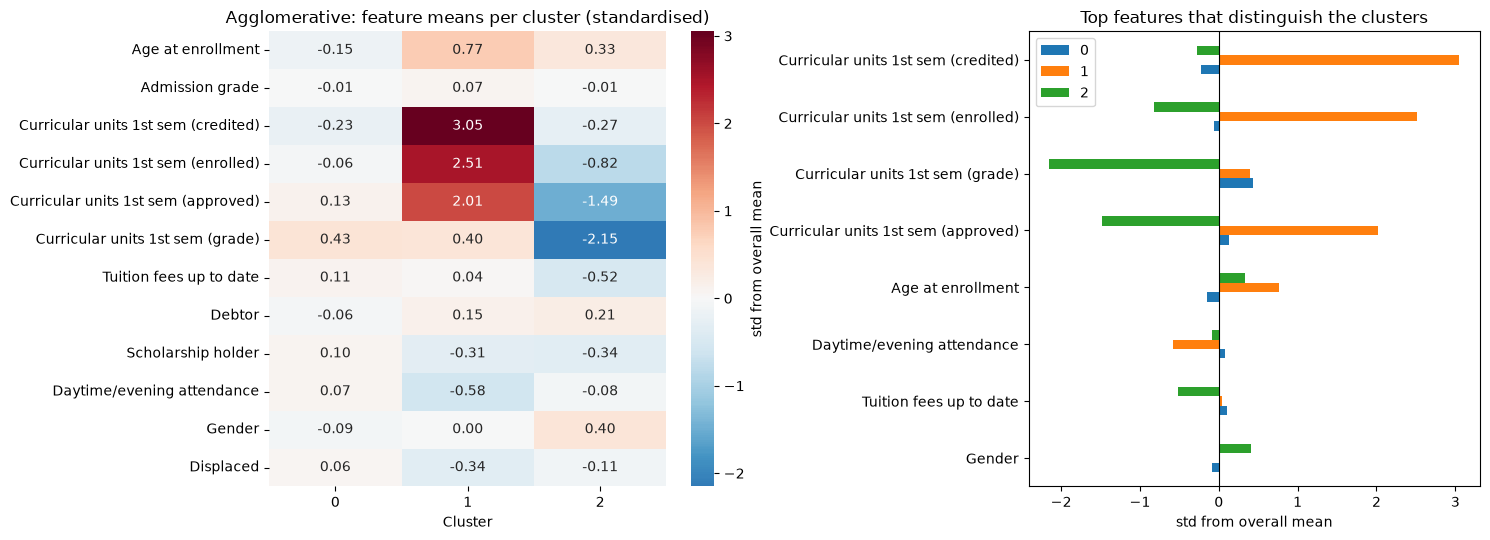

In [20]:
profile_cols = ["Age at enrollment", "Admission grade",
                "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
                "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
                "Tuition fees up to date", "Debtor", "Scholarship holder",
                "Daytime/evening attendance", "Gender", "Displaced"]

lab = labels["Agglomerative (Ward)"]
means = raw[profile_cols].groupby(lab).mean()
means["Students"] = np.bincount(lab)
means = means.join(pd.crosstab(lab, y_true, normalize="index").add_suffix(" rate"))
display(means.round(2).T)

# Standardised difference from the overall mean (feature importance per cluster)
z = (raw[profile_cols].groupby(lab).mean() - raw[profile_cols].mean()) / raw[profile_cols].std()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
sns.heatmap(z.T, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0], cbar_kws={"label": "std from overall mean"})
axes[0].set_title("Agglomerative: feature means per cluster (standardised)"); axes[0].set_xlabel("Cluster")

top = z.abs().max().sort_values(ascending=True).tail(8).index
z[top].T.plot(kind="barh", ax=axes[1], color=sns.color_palette("tab10", K))
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Top features that distinguish the clusters"); axes[1].set_xlabel("std from overall mean")
plt.tight_layout(); plt.savefig(PLOTS / "cluster_feature_importance.png", dpi=150); plt.show()

pd.DataFrame({"agglomerative_cluster": lab, "kmeans_cluster": labels["K-Means"]}).to_csv(
    OUTPUTS / "cluster_labels_both_algorithms.csv", index_label="row_id")

## 5. Cluster Interpretation & Profiles

### 5.1 K-Means cluster profiles

The table below shows the average of each feature inside every K-Means cluster, in the **original units** from `data.csv` (age in years, grades out of 20, and so on), together with the cluster size and the real outcomes of its students. The outcomes were **not** used to build the clusters; they are shown only to understand what each group means. Each cluster is named from its characteristics.

In [21]:
# ============================================================
# 5.1 K-Means cluster profiles (original units)
# ============================================================
profile_cols = ["Age at enrollment", "Admission grade",
                "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
                "Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
                "Tuition fees up to date", "Debtor", "Scholarship holder",
                "Daytime/evening attendance", "Gender", "Displaced"]

km_labels = kmeans_final.labels_
km_means = raw[profile_cols].groupby(km_labels).mean()
km_means["Students"] = np.bincount(km_labels)
km_means["Share of cohort"] = km_means["Students"] / len(km_labels)
km_means = km_means.join(
    pd.crosstab(km_labels, y_true, normalize="index")[["Dropout", "Enrolled", "Graduate"]].add_suffix(" rate"))

# Name each cluster from its characteristics, so the names do not depend on the cluster numbering
approved_col = "Curricular units 1st sem (approved)"
credited_col = "Curricular units 1st sem (credited)"
no_progress_id = km_means[approved_col].idxmin()
mature_id = km_means[credited_col].idxmax()
regular_id = [c for c in km_means.index if c not in (no_progress_id, mature_id)][0]
assert len({no_progress_id, mature_id, regular_id}) == 3, "the three profiles must be different clusters"
cluster_names = {int(regular_id): "Regular on-track students",
                 int(mature_id): "Mature transfer / credited students",
                 int(no_progress_id): "No-progress students"}

display(km_means.rename(index=cluster_names).round(2).T)

,Mature transfer / credited students,Regular on-track students,No-progress students
Age at enrollment,29.27,22.21,25.81
Admission grade,129.33,126.80,126.87
Curricular units 1st sem (credited),8.55,0.19,0.00
Curricular units 1st sem (enrolled),13.08,6.14,4.17
Curricular units 1st sem (approved),11.45,5.13,0.01
Curricular units 1st sem (grade),12.62,12.71,0.08
Tuition fees up to date,0.89,0.92,0.70
Debtor,0.15,0.10,0.18
Scholarship holder,0.11,0.29,0.10
Daytime/evening attendance,0.73,0.91,0.87


**K-Means cluster profiles** (cluster numbers may differ from the Agglomerative model; the groups are the same):

| Profile | Who they are | Outcome | Advisory meaning |
|---|---|---|---|
| **Regular on-track students** (3,409 students, 77%) | Young (about 22), mostly day-time, a normal load of about 6 enrolled units, about 5 passed, grade about 12.7/20, 29% have a scholarship | 57% Graduate, 23% Dropout, 20% Enrolled | Standard monitoring. The cluster alone cannot tell who will drop out, so the Random Forest is needed here. |
| **Mature transfer / credited students** (291 students, 7%) | Older (about 29), many units credited from previous studies (about 8.6), a heavy load (about 13 enrolled, 11 passed), more evening classes (27%) | 62% Graduate, 25% Dropout | Different needs (work or family): flexible scheduling rather than academic remediation. |
| **No-progress students** (724 students, 16%) | Enrolled in about 4 units but passed almost none (0.01 on average), grade about 0, only 70% have tuition fees up to date, 18% are debtors | **80% Dropout**, 11% Graduate | Highest priority: early outreach, an academic recovery plan and a tuition-status check with student services. |

The cluster that matters most for advisors is the **no-progress group**: it is only 16% of students but has by far the highest dropout rate. The clusters describe patterns that already exist in the 1st-semester data; they do not prove why students drop out, and they should be used to prioritize support, never to restrict a student's opportunities.

In [22]:
# ============================================================
# 5.1 (continued) Save the cluster model and the cluster profiles for the dashboard and the AI briefings
# ============================================================
import sys, json, joblib, warnings
from sklearn.pipeline import Pipeline
from sklearn.exceptions import InconsistentVersionWarning

# Needed so the saved Phase 1 preprocessing can be loaded (Supervised_Learning.rf_pipeline_utils)
sys.path.insert(0, str(ROOT.resolve()))

# rf_pipeline.joblib was saved with scikit-learn 1.6.1. Loading it with another version prints
# many harmless version warnings, so they are hidden here (the check below confirms the result).
with warnings.catch_warnings():
    warnings.simplefilter("ignore", InconsistentVersionWarning)
    rf_pipe = joblib.load(ROOT / "Supervised_Learning" / "models" / "rf_pipeline.joblib")

# Same K-Means model as above, fitted again on a table with column names, so the pipeline
# can be given a table later without warnings. The labels must be identical.
kmeans_saved = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(
    pd.DataFrame(X, columns=feature_names))
assert (kmeans_saved.labels_ == kmeans_final.labels_).all()

# One pipeline: raw student record -> Phase 1 preprocessing -> K-Means -> cluster number
cluster_model = Pipeline([("preprocess", rf_pipe.named_steps["preprocess"]),
                          ("kmeans", kmeans_saved)])
joblib.dump(cluster_model, OUTPUTS / "cluster_model.joblib", compress=3)

# Check: the saved pipeline gives every student the same cluster as the notebook did.
# (data.csv is read with sep=";" here, the same way as in the Phase 1 pipeline code)
students_raw = pd.read_csv(ROOT / "Dataset" / "data.csv", sep=";")
students_raw.columns = students_raw.columns.str.strip()
reloaded = joblib.load(OUTPUTS / "cluster_model.joblib")
check = reloaded.predict(students_raw.drop(columns="Target"))
assert (check == kmeans_final.labels_).all()
print("cluster_model.joblib saved and checked on", len(check), "students")

# ---- cluster_profiles.json: one entry per cluster, keyed by the cluster number ----
descriptions = {
    "Regular on-track students": "Younger, mostly day-time students with a normal first-semester load who passed most of their units.",
    "Mature transfer / credited students": "Older students with many units credited from previous studies, a heavy first-semester load and more evening classes.",
    "No-progress students": "Students who enrolled in first-semester units but passed almost none of them, with a first-semester grade of about zero.",
}
support = {
    "Regular on-track students": "Standard monitoring. The cluster alone cannot show who is at risk, so use the model prediction.",
    "Mature transfer / credited students": "Offer flexible scheduling and check workload and work or family constraints; academic remediation is usually not the main need.",
    "No-progress students": "Highest priority for early outreach: an academic recovery plan and a check of tuition status with student services.",
}

profiles = {}
for cid, name in cluster_names.items():
    r = km_means.loc[cid]
    profiles[str(cid)] = {
        "cluster_id": int(cid),
        "name": name,
        "description": descriptions[name],
        "students": int(r["Students"]),
        "share_of_cohort": round(float(r["Share of cohort"]), 3),
        "dropout_rate": round(float(r["Dropout rate"]), 3),
        "still_enrolled_rate": round(float(r["Enrolled rate"]), 3),
        "graduate_rate": round(float(r["Graduate rate"]), 3),
        "typical_student": {
            "average_age_at_enrollment": round(float(r["Age at enrollment"]), 1),
            "average_units_enrolled_1st_sem": round(float(r["Curricular units 1st sem (enrolled)"]), 1),
            "average_units_approved_1st_sem": round(float(r["Curricular units 1st sem (approved)"]), 1),
            "average_units_credited_1st_sem": round(float(r["Curricular units 1st sem (credited)"]), 1),
            "average_grade_1st_sem": round(float(r["Curricular units 1st sem (grade)"]), 1),
            "share_with_tuition_up_to_date": round(float(r["Tuition fees up to date"]), 2),
            "share_in_evening_classes": round(1 - float(r["Daytime/evening attendance"]), 2),
        },
        "suggested_support": support[name],
    }

with open(OUTPUTS / "cluster_profiles.json", "w", encoding="utf-8") as f:
    json.dump(profiles, f, indent=2, ensure_ascii=False)

print("cluster_profiles.json saved. Clusters:", {k: v["name"] for k, v in profiles.items()})

cluster_model.joblib saved and checked on 4424 students
cluster_profiles.json saved. Clusters: {'1': 'Regular on-track students', '0': 'Mature transfer / credited students', '2': 'No-progress students'}


**Saved files for the rest of the system** (`Unsupervised_Learning/outputs/`):
- `cluster_model.joblib` – a scikit-learn pipeline: Phase 1 preprocessing followed by K-Means (`K = 3`). It takes a **raw** student record (the same columns as `Dataset/data.csv`) and returns the cluster number.
- `cluster_profiles.json` – for each cluster number: name, description, size, outcome rates, a typical student and the suggested support.

Example of how the dashboard and the AI briefings use them (run from the repository root):

```python
cluster_model = joblib.load("Unsupervised_Learning/outputs/cluster_model.joblib")
profiles = json.load(open("Unsupervised_Learning/outputs/cluster_profiles.json"))
cid = int(cluster_model.predict(student_row)[0])   # student_row: one row with the data.csv columns
cluster_profile = profiles[str(cid)]               # pass this to generate_briefing(...)
```

### 5.2 Agglomerative cluster profiles

**Agglomerative cluster profiles** (cluster numbers may differ from K-Means; the groups are the same):

| Profile | Who they are | Outcome | Advisory meaning |
|---|---|---|---|
| **Regular on-track students** (largest, ~76%) | Young (~22), day-time, full normal load, pass most units, grade ≈12.7/20 | ~57% Graduate, ~23% Dropout | Standard monitoring; the RF model is needed here because the cluster alone cannot tell who will drop out |
| **Mature transfer / credited students** (~7%) | Older (~29), many units credited from previous studies, high enrolled and approved units, more evening classes | ~60% Graduate | Different needs (work/family); flexible scheduling rather than academic remediation |
| **No-progress students** (~16%) | Enrolled but passed almost no units, grade ≈0, fewer students with tuition fees up to date (71% vs 92%) and more debtors (18% vs 9%) | **~80% Dropout** | Highest priority for immediate outreach, an academic recovery plan and a tuition-status check with student services |

## 6. Integration Strategy – how the clusters enhance the system

1. **Deployed clustering model = K-Means.** It reaches the same structure as Agglomerative clustering (high ARI) and can assign a new
   student with `predict()`. It is saved as `Unsupervised_Learning/outputs/cluster_model.joblib` together with
   `cluster_profiles.json` (name, description, dropout rate of each cluster).
2. **Dashboard – cohort segmentation.** The KPI page shows retention per cluster, so a dean sees immediately that one segment
   (no-progress students) carries most of the dropout risk.
3. **Dashboard – student simulator.** After the Random Forest predicts the outcome, the simulated student is also assigned to a cluster,
   and the cluster profile is shown next to the prediction. Moving the GPA/attendance sliders can move the student between clusters,
   which makes the "trajectory" visible.
4. **Generative AI – personalization.** The cluster profile is passed into the prompt (`{cluster_profile}` placeholder), so the counseling
   outreach summary is tailored (e.g., flexible-schedule advice for mature students, a recovery plan and a tuition-status check for the no-progress group).
5. **Rule-based early alert.** Membership in the no-progress cluster (~80% dropout) is a simple, explainable flag that complements the
   Random Forest probabilities.
6. **Cluster as a model feature.** Section 6.1 tests adding the cluster label to the Random Forest. It did not improve the model (cross-validation macro F1 0.698 without and 0.697 with the cluster label), so the clusters are used for segmentation and explanation, not as an extra input to the forest.

### 6.1 Integration test: Random Forest with and without the cluster label

To test whether the clusters can improve the supervised model, we add the K-Means cluster number (as three 0/1 columns) to the Random Forest's inputs and compare it with the same Random Forest without the cluster columns.

- **Same Random Forest settings** in both cases (the tuned Phase 1 settings), and the same Phase 1 train/test split.
- **No data leakage:** K-Means is fitted on the training students only. During cross-validation it is re-fitted inside every fold, using only that fold's training part, and the validation students are only assigned to the nearest cluster.
- **Metrics:** accuracy, macro F1 and the F1 of the Enrolled class (the hardest class), because the classes are imbalanced.

In [23]:
# ============================================================
# 6.1 Integration test: Random Forest with and without the cluster label
# ============================================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score

# Tuned Random Forest settings from Phase 1 (same for both settings below)
RF_PARAMS = dict(n_estimators=200, max_depth=None, min_samples_split=10,
                 class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)

# Same train/test split as Phase 1 (the "split" column)
train_mask = (df["split"] == "train").values
X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = df.loc[train_mask, "Target"].values, df.loc[~train_mask, "Target"].values  # 0=Dropout, 1=Enrolled, 2=Graduate

def add_cluster_feature(X_fit, others, k=K):
    """Fit K-Means on X_fit ONLY, then add the cluster number (one-hot) to X_fit and to every matrix in `others`."""
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_fit)
    add = lambda M: np.hstack([M, np.eye(k)[km.predict(M)]])
    return add(X_fit), [add(M) for M in others]

def scores(y_true_, y_pred_):
    f1_per_class = f1_score(y_true_, y_pred_, average=None, labels=[0, 1, 2])
    return {"Accuracy": accuracy_score(y_true_, y_pred_),
            "Macro F1": f1_per_class.mean(),
            "Enrolled F1": f1_per_class[1]}

# ---- (a) 5-fold cross-validation on the training students (clusters are re-fitted inside every fold) ----
cv_rows = []
for train_idx, val_idx in StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train):
    Xtr_c, (Xva_c,) = add_cluster_feature(X_train[train_idx], [X_train[val_idx]])
    settings = {"Without cluster feature": (X_train[train_idx], X_train[val_idx]),
                "With cluster feature": (Xtr_c, Xva_c)}
    for name, (A, B) in settings.items():
        rf = RandomForestClassifier(**RF_PARAMS).fit(A, y_train[train_idx])
        cv_rows.append({"Setting": name, **scores(y_train[val_idx], rf.predict(B))})
cv_df = pd.DataFrame(cv_rows)
cv_summary = cv_df.groupby("Setting").agg(["mean", "std"]).round(3)
print("5-fold cross-validation on the training set (mean and std over 5 folds)")
display(cv_summary.loc[["Without cluster feature", "With cluster feature"]])

fold_gain = (cv_df[cv_df["Setting"] == "With cluster feature"]["Macro F1"].values
             - cv_df[cv_df["Setting"] == "Without cluster feature"]["Macro F1"].values)
print(f"Macro F1 change per fold (with minus without): {np.round(fold_gain, 3)}  mean = {fold_gain.mean():+.3f}")

# ---- (b) Final check on the 885 test students (K-Means fitted on the training students only) ----
Xtr_c, (Xte_c,) = add_cluster_feature(X_train, [X_test])
test_rows = []
for name, (A, B) in {"Without cluster feature": (X_train, X_test), "With cluster feature": (Xtr_c, Xte_c)}.items():
    rf = RandomForestClassifier(**RF_PARAMS).fit(A, y_train)
    test_rows.append({"Setting": name, **scores(y_test, rf.predict(B))})
test_df = pd.DataFrame(test_rows).set_index("Setting").round(3)
print("\nTest set (885 students)")
display(test_df)

5-fold cross-validation on the training set (mean and std over 5 folds)


Accuracy        Macro F1        Enrolled F1       
                            mean    std     mean    std        mean    std
Setting                                                                   
Without cluster feature    0.747  0.004    0.698  0.006       0.492  0.025
With cluster feature       0.745  0.009    0.697  0.008       0.498  0.022

Macro F1 change per fold (with minus without): [-0.006  0.002  0.006 -0.005  0.002]  mean = -0.000

Test set (885 students)


,Accuracy,Macro F1,Enrolled F1
Setting,,,
Without cluster feature,0.727,0.678,0.473
With cluster feature,0.730,0.680,0.471


**Results of the integration test**

| Setting | CV macro F1 (mean ± std) | CV Enrolled F1 | Test macro F1 | Test Enrolled F1 |
|---|---|---|---|---|
| Random Forest without cluster feature | 0.698 ± 0.006 | 0.492 | 0.678 | 0.473 |
| Random Forest with cluster feature | 0.697 ± 0.008 | 0.498 | 0.680 | 0.471 |

- **Adding the cluster label does not improve the Random Forest.** In cross-validation, the macro F1 change per fold goes in both directions (−0.006 to +0.006) and averages 0.000, and on the test set the difference in macro F1 is only +0.002, well within the fold-to-fold variation (standard deviation 0.006–0.008).
- **The Enrolled class does not improve either** (F1 about 0.47–0.50 in both settings), so the clusters do not help with the hardest class.
- **Why:** the clusters are built from the same 1st-semester and background features that the Random Forest already uses, so the cluster number gives the forest almost no information it does not already have.
- **Conclusion:** we do **not** add the cluster label as an input to the final Random Forest. The value of the clusters is in **segmentation and explanation** instead: the cohort view in the dashboard, the cluster profile shown next to a student's prediction, and the personalization of the AI briefings (Section 6, points 2–5).

*Note:* the absolute numbers here can differ slightly from the Phase 1 table, because Random Forest results change a little with the scikit-learn version. The comparison is still fair, because both settings are run here with the same settings, data split and library version.

## 7. Challenges & Limitations

- **High-dimensional, mostly binary data.** 102 features, most of them one-hot. Distances become less informative, which explains the modest
  silhouette (≈0.2) for both algorithms.
- **Clusters do not separate "Enrolled".** Enrolled students sit inside the large regular cluster with future graduates. This mirrors the
  Phase 1 finding that Enrolled is the hardest class.
- **Clusters are dominated by academic features.** About 92% of the between-cluster variation comes from the first-semester unit and grade features (Section 5.1), and the 79 one-hot category columns (course, parents' occupation and so on) explain only 1.5%. Feature selection or weighting before clustering could give finer segments (future work).
- **K-Means on one-hot data.** The course slides note that K-Means is designed for numeric attributes. Our one-hot columns are a workaround, and K-Modes or K-Prototypes would be more natural for mixed data (future work).
- **Agglomerative scalability.** O(n²) memory and no `predict()` for new students; fine for 4,424 records but not for a live system.
- **Choice of k is a trade-off.** k = 2 scores best on silhouette but is not useful for advising; we chose k = 3 for interpretability.
- **Associations, not causes.** A cluster with high dropout identifies who needs support; it does not prove why students drop out.
- **Ethics.** Cluster labels must not become fixed "labels" for students. They are used to prioritize support, never to restrict opportunities.

In [24]:
# ============================================================
# Which features define the K-Means clusters? (share of the between-cluster variation)
# ============================================================
overall_mean = X.mean(axis=0)
between = np.zeros(X.shape[1])
for c in range(K):
    members = X[kmeans_final.labels_ == c]
    between += len(members) * (members.mean(axis=0) - overall_mean) ** 2
between_share = pd.Series(between / between.sum(), index=feature_names).sort_values(ascending=False)

print("Top 5 features and the share (%) of the between-cluster variation they explain:")
print((between_share.head(5) * 100).round(1).to_string())
print(f"\nAll first-semester unit features together: {between_share.filter(like='1st sem').sum():.0%}")
onehot_cols = [c for c in feature_names if c.startswith(("Course_", "Marital status_", "Application mode_", "Previous qualification_",
                                                         "Nacionality_", "Mother", "Father"))]
print(f"All {len(onehot_cols)} one-hot category columns together: {between_share[onehot_cols].sum():.1%}")

Top 5 features and the share (%) of the between-cluster variation they explain:
Curricular units 1st sem (grade)          24.5
Curricular units 1st sem (credited)       20.4
Curricular units 1st sem (approved)       18.7
Curricular units 1st sem (enrolled)       16.2
Curricular units 1st sem (evaluations)    12.0

All first-semester unit features together: 92%
All 79 one-hot category columns together: 1.5%


In [25]:
# ============================================================
# Dataset/clustered_data.csv (data with cluster labels) and cluster_profiles.txt (readable summary)
# ============================================================
clustered = students_raw.copy()                      # original data, same row order as data.csv
clustered["cluster"] = kmeans_final.labels_          # K-Means cluster number
clustered["cluster_name"] = clustered["cluster"].map(cluster_names)
clustered.to_csv(ROOT / "Dataset" / "clustered_data.csv", index=False)
print("Dataset/clustered_data.csv saved:", clustered.shape)

lines = ["K-MEANS CLUSTER PROFILES (K = 3)", "=" * 34, ""]
for cid in sorted(profiles, key=lambda k: -profiles[k]["students"]):
    p, t = profiles[cid], profiles[cid]["typical_student"]
    lines += [
        f"Cluster {cid}: {p['name']} ({p['students']} students, {p['share_of_cohort']:.0%} of the cohort)",
        f"  {p['description']}",
        f"  Outcomes: {p['graduate_rate']:.0%} Graduate, {p['dropout_rate']:.0%} Dropout, {p['still_enrolled_rate']:.0%} still enrolled",
        f"  Typical student: age {t['average_age_at_enrollment']}, {t['average_units_enrolled_1st_sem']} units enrolled and "
        f"{t['average_units_approved_1st_sem']} approved in the 1st semester, 1st-semester grade {t['average_grade_1st_sem']}",
        f"  Suggested support: {p['suggested_support']}",
        "",
    ]
(ROOT / "Unsupervised_Learning" / "cluster_profiles.txt").write_text("\n".join(lines), encoding="utf-8")
print("Unsupervised_Learning/cluster_profiles.txt saved")

Dataset/clustered_data.csv saved: (4424, 39)
Unsupervised_Learning/cluster_profiles.txt saved
